loading subsets into RAM ...
CAL=100000  CLF=100000  TEST=100000

RMF labeling: 3384 of 50000 |1> calibration shots labeled relaxation (6.77%)   R=118.77

[Baseline] Boxcar + linear threshold (full test): F0=0.9750 F1=0.9407 F=0.9578

=== Assignment fidelity on full test set ===
 EMA alpha |   MF sum  MF 2-feat  MF+RMF 4-feat
      None |   0.9570     0.9570         0.9592   (4-feat F0=0.9751, F1=0.9433)
       0.2 |   0.9570     0.9570         0.9597   (4-feat F0=0.9763, F1=0.9432)
      0.05 |   0.9566     0.9566         0.9599   (4-feat F0=0.9761, F1=0.9437)
      0.01 |   0.9546     0.9546         0.9594   (4-feat F0=0.9765, F1=0.9424)

=== Matched-filter fidelity vs accumulation length T (bins) ===
 EMA alpha |     77    154    192    270    385    500    578    693    770
      None | 0.5957 0.7863 0.8548 0.9274 0.9564 0.9606 0.9597 0.9582 0.9570
       0.2 | 0.5959 0.7868 0.8550 0.9274 0.9563 0.9604 0.9597 0.9580 0.9570
      0.05 | 0.5949 0.7860 0.8540 0.9268 0.9560 0.9601 0.95

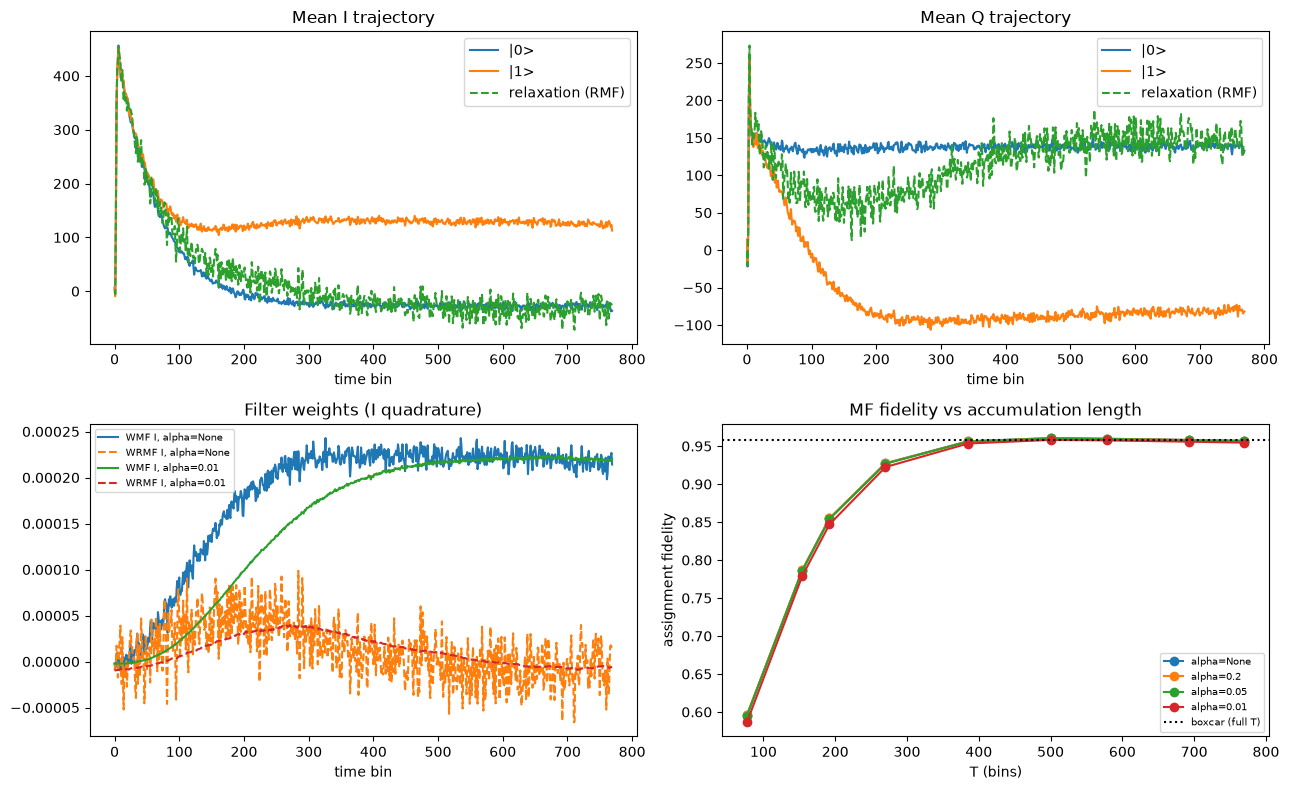


saved step2_filters.npz and step1_2_results.png


In [2]:
"""
Step 1 + 2: baselines, EMA, State Matched Filter (WMF), Relaxation Matched Filter (WRMF).
Float64 reference. Layout is interleaved [I0,Q0,I1,Q1,...] (confirmed in Step 0).

Data splits (all from the train file, test file is untouched until evaluation):
  CAL : filters / centroids / RMF labeling are derived here (10k per class, as in the spec)
  CLF : thresholds and linear classifier are fit here
  TEST: full 100k test shots, evaluation only
"""
import os
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ config
DATA_DIR = r"D:\MSU\Qubit_readout_FPGA"
N_SAMPLES = 770
N_CAL_PER_CLASS = 50_000
N_CLF = 100_000
CH = 20_000                       # rows per processing chunk
SEED = 0
EMA_ALPHAS = [None, 0.2, 0.05, 0.01]   # None = no EMA; 0.01 is the spec value
T_FRACS = [0.1, 0.2, 0.25, 0.35, 0.5, 0.65, 0.75, 0.9, 1.0]
RIDGE_LAMBDA = 1e-3

Ts = np.unique(np.round(N_SAMPLES * np.array(T_FRACS)).astype(int))


def p(name):
    return os.path.join(DATA_DIR, name)


# ------------------------------------------------------------------ load + split
Xtr = np.load(p("0528_X_train_0_770.npy"), mmap_mode="r")
Xte_m = np.load(p("0528_X_test_0_770.npy"), mmap_mode="r")
ytr = np.load(p("0528_y_train_0_770.npy")).astype(int)
yte = np.load(p("0528_y_test_0_770.npy")).astype(int)

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(ytr))
cal_idx = np.concatenate([perm[ytr[perm] == c][:N_CAL_PER_CLASS] for c in (0, 1)])
mask = np.ones(len(ytr), bool)
mask[cal_idx] = False
clf_idx = perm[mask[perm]][:N_CLF]
cal_idx, clf_idx = np.sort(cal_idx), np.sort(clf_idx)
assert len(np.intersect1d(cal_idx, clf_idx)) == 0


def load_rows(X, idx, dtype):
    out = np.empty((len(idx), X.shape[1]), dtype)
    for i in range(0, len(idx), CH):
        out[i:i + CH] = X[idx[i:i + CH]]
    return out


print("loading subsets into RAM ...")
Xcal = load_rows(Xtr, cal_idx, np.float64)
ycal = ytr[cal_idx]
Xclf = load_rows(Xtr, clf_idx, np.float32)
yclf = ytr[clf_idx]
Xte = load_rows(Xte_m, np.arange(len(yte)), np.float32)
print(f"CAL={len(ycal)}  CLF={len(yclf)}  TEST={len(yte)}")


# ------------------------------------------------------------------ helpers
def best_threshold(s, y):
    """Threshold maximizing accuracy on (s, y); class 1 expected to score higher."""
    order = np.argsort(s)
    ss, ys = s[order], y[order]
    n0 = (ys == 0).sum()
    c1 = np.r_[0, np.cumsum(ys == 1)]
    c0 = np.r_[0, np.cumsum(ys == 0)]
    err = c1 + (n0 - c0)               # k lowest scores predicted as class 0
    k = int(np.argmin(err))
    if k == 0:
        return ss[0] - 1.0
    if k == len(ss):
        return ss[-1]
    return 0.5 * (ss[k - 1] + ss[k])


def fid(s, y, thr):
    pred = s > thr
    f0 = np.mean(~pred[y == 0])
    f1 = np.mean(pred[y == 1])
    return f0, f1, 0.5 * (f0 + f1)


def ema(x, alpha):
    out = np.empty_like(x)
    out[0] = x[0]
    for t in range(1, len(x)):
        out[t] = alpha * x[t] + (1 - alpha) * out[t - 1]
    return out


def stats(I, Q):
    """(meanI, meanQ, varI, varQ) per time bin."""
    return I.mean(0), Q.mean(0), I.var(0), Q.var(0)


def make_filter(A, B, alpha):
    """Diagonal-covariance matched filter weights for I and Q: (mean diff)/(pooled var).
    EMA (if any) is applied to the mean-difference trajectory, as in the spec."""
    w = []
    for k in (0, 1):
        d = B[k] - A[k]
        if alpha:
            d = ema(d, alpha)
        w.append(d / (0.5 * (A[2 + k] + B[2 + k])))
    return w


def boxcar(X):
    return np.c_[X[:, 0::2].mean(1), X[:, 1::2].mean(1)]


def features(X, Wmf, Wrmf):
    """Returns F4 (N,4) = [sum wI_mf*I, sum wQ_mf*Q, sum wI_rmf*I, sum wQ_rmf*Q]
    and mfT (N, len(Ts)) = running MF score truncated at each T in Ts."""
    wmf = [w.astype(np.float32) for w in Wmf]
    wrmf = [w.astype(np.float32) for w in Wrmf]
    N = len(X)
    F4 = np.empty((N, 4), np.float64)
    mfT = np.empty((N, len(Ts)), np.float64)
    for i in range(0, N, CH):
        x = X[i:i + CH]
        I, Q = x[:, 0::2], x[:, 1::2]
        pI, pQ = I * wmf[0], Q * wmf[1]
        F4[i:i + CH, 0] = pI.sum(1)
        F4[i:i + CH, 1] = pQ.sum(1)
        F4[i:i + CH, 2] = (I * wrmf[0]).sum(1)
        F4[i:i + CH, 3] = (Q * wrmf[1]).sum(1)
        mfT[i:i + CH] = np.cumsum(pI + pQ, axis=1, dtype=np.float64)[:, Ts - 1]
    return F4, mfT


def ridge_fit(F, y, lam=RIDGE_LAMBDA):
    mu, sd = F.mean(0), F.std(0)
    Z = np.c_[np.ones(len(F)), (F - mu) / sd]
    t = 2.0 * y - 1.0
    w = np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ t)
    return mu, sd, w


def ridge_score(F, m):
    mu, sd, w = m
    return np.c_[np.ones(len(F)), (F - mu) / sd] @ w


def eval_scores(s_clf, s_te):
    thr = best_threshold(s_clf, yclf)
    return fid(s_te, yte, thr)


# ------------------------------------------------------------------ calibration stats
Ic, Qc = Xcal[:, 0::2], Xcal[:, 1::2]
S0 = stats(Ic[ycal == 0], Qc[ycal == 0])
S1 = stats(Ic[ycal == 1], Qc[ycal == 1])

# RMF labeling (Algorithm 1): |1> shots whose mean trace value (MTV) lies within R of C0
mtv = np.c_[Ic.mean(1), Qc.mean(1)]
C0, C1 = mtv[ycal == 0].mean(0), mtv[ycal == 1].mean(0)
R = 0.5 * np.linalg.norm(C0 - C1)
relax = (ycal == 1) & (np.linalg.norm(mtv - C0, axis=1) < R)
n1 = (ycal == 1).sum()
print(f"\nRMF labeling: {relax.sum()} of {n1} |1> calibration shots labeled relaxation "
      f"({100 * relax.sum() / n1:.2f}%)   R={R:.2f}")
if relax.sum() < 50:
    raise RuntimeError(
        f"Only {relax.sum()} relaxation traces labeled; RMF is not meaningful. "
        "Check labels/layout or adjust the radius R."
    )
SR = stats(Ic[relax], Qc[relax])

# ------------------------------------------------------------------ baseline: boxcar
Bc, Bt = boxcar(Xclf), boxcar(Xte)
wB = Bc[yclf == 1].mean(0) - Bc[yclf == 0].mean(0)
f0, f1, F = eval_scores(Bc @ wB, Bt @ wB)
print(f"\n[Baseline] Boxcar + linear threshold (full test): F0={f0:.4f} F1={f1:.4f} F={F:.4f}")

# ------------------------------------------------------------------ filters, per EMA alpha
res = {}
print("\n=== Assignment fidelity on full test set ===")
print(f"{'EMA alpha':>10s} | {'MF sum':>8s} {'MF 2-feat':>10s} {'MF+RMF 4-feat':>14s}")
for a in EMA_ALPHAS:
    Wmf = make_filter(S0, S1, a)
    Wrmf = make_filter(S0, SR, a)
    Fc, mfTc = features(Xclf, Wmf, Wrmf)
    Ft, mfTt = features(Xte, Wmf, Wrmf)

    _, _, F_mf = eval_scores(mfTc[:, -1], mfTt[:, -1])
    m2 = ridge_fit(Fc[:, :2], yclf)
    _, _, F_2 = eval_scores(ridge_score(Fc[:, :2], m2), ridge_score(Ft[:, :2], m2))
    m4 = ridge_fit(Fc, yclf)
    f0_4, f1_4, F_4 = eval_scores(ridge_score(Fc, m4), ridge_score(Ft, m4))

    T_fid = [eval_scores(mfTc[:, j], mfTt[:, j])[2] for j in range(len(Ts))]
    res[a] = dict(Wmf=Wmf, Wrmf=Wrmf, F_mf=F_mf, F_2=F_2, F_4=F_4, T_fid=T_fid)
    print(f"{str(a):>10s} | {F_mf:8.4f} {F_2:10.4f} {F_4:14.4f}   (4-feat F0={f0_4:.4f}, F1={f1_4:.4f})")

print("\n=== Matched-filter fidelity vs accumulation length T (bins) ===")
print(f"{'EMA alpha':>10s} | " + " ".join(f"{t:6d}" for t in Ts))
for a in EMA_ALPHAS:
    print(f"{str(a):>10s} | " + " ".join(f"{v:6.4f}" for v in res[a]["T_fid"]))
print("Boxcar reference above; compare against the T=770 column.")

# ------------------------------------------------------------------ plots
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
tt = np.arange(N_SAMPLES)
for k, nm in enumerate(["I", "Q"]):
    ax[0, k].plot(tt, S0[k], label="|0>")
    ax[0, k].plot(tt, S1[k], label="|1>")
    ax[0, k].plot(tt, SR[k], "--", label="relaxation (RMF)")
    ax[0, k].set_title(f"Mean {nm} trajectory")
    ax[0, k].set_xlabel("time bin")
    ax[0, k].legend()
for a in (None, 0.01):
    ax[1, 0].plot(tt, res[a]["Wmf"][0], label=f"WMF I, alpha={a}")
    ax[1, 0].plot(tt, res[a]["Wrmf"][0], "--", label=f"WRMF I, alpha={a}")
ax[1, 0].set_title("Filter weights (I quadrature)")
ax[1, 0].set_xlabel("time bin")
ax[1, 0].legend(fontsize=7)
for a in EMA_ALPHAS:
    ax[1, 1].plot(Ts, res[a]["T_fid"], marker="o", label=f"alpha={a}")
ax[1, 1].axhline(F, color="k", ls=":", label="boxcar (full T)")
ax[1, 1].set_title("MF fidelity vs accumulation length")
ax[1, 1].set_xlabel("T (bins)")
ax[1, 1].set_ylabel("assignment fidelity")
ax[1, 1].legend(fontsize=7)
plt.tight_layout()
plt.savefig("step1_2_results.png", dpi=130)
plt.show()

# ------------------------------------------------------------------ save for later steps
np.savez(
    "step2_filters.npz",
    cal_idx=cal_idx, clf_idx=clf_idx,
    **{f"Wmf_I_a{a}": res[a]["Wmf"][0] for a in EMA_ALPHAS},
    **{f"Wmf_Q_a{a}": res[a]["Wmf"][1] for a in EMA_ALPHAS},
    **{f"Wrmf_I_a{a}": res[a]["Wrmf"][0] for a in EMA_ALPHAS},
    **{f"Wrmf_Q_a{a}": res[a]["Wrmf"][1] for a in EMA_ALPHAS},
)
print("\nsaved step2_filters.npz and step1_2_results.png")